In [1]:

import os
import sys

# Use the same Python interpreter for Spark workers
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

print("Python executable:", sys.executable)
print("Spark worker Python:", os.environ["PYSPARK_PYTHON"])


Python executable: c:\Users\Lenovo\.conda\envs\movie-spark\python.exe
Spark worker Python: c:\Users\Lenovo\.conda\envs\movie-spark\python.exe


In [2]:

from pyspark.sql import SparkSession

spark = SparkSession.builder \
    .appName("MovieRecommendationSystem") \
    .master("local[2]") \
    .config("spark.driver.host", "127.0.0.1") \
    .config("spark.driver.bindAddress", "127.0.0.1") \
    .getOrCreate()

print("Spark Version:", spark.version)
print("Spark Session Created Successfully!")


Spark Version: 3.5.6
Spark Session Created Successfully!


In [3]:

import os
import sqlite3

# Check database file
db_path = os.path.abspath("movielens-small.db")

print("Database path:", db_path)
print("Database exists:", os.path.exists(db_path))

# Connect to database
if os.path.exists(db_path):
    con = sqlite3.connect(db_path)
    cursor = con.cursor()
    print("Database connected successfully!")
else:
    print("Database file not found!")


Database path: d:\movie_recommendation_system-main\movielens-small.db
Database exists: True
Database connected successfully!


In [4]:

cursor.execute("""
    SELECT name
    FROM sqlite_master
    WHERE type='table';
""")

tables = cursor.fetchall()

print("Available tables:")
for table in tables:
    print(table[0])


Available tables:
movies
ratings
links
tags
movie_ratings
movies_2


In [5]:

for table in tables:
    table_name = table[0]

    cursor.execute(f'SELECT COUNT(*) FROM "{table_name}"')
    count = cursor.fetchone()[0]

    print(f"{table_name}: {count} records")


movies: 8570 records
ratings: 100023 records
links: 8570 records
tags: 2488 records
movie_ratings: 100023 records
movies_2: 8570 records


In [6]:

# Display first 5 movies
cursor.execute("SELECT * FROM movies LIMIT 5")
print("Movies:")
for row in cursor.fetchall():
    print(row)

# Display first 5 ratings
cursor.execute("SELECT * FROM ratings LIMIT 5")
print("\nRatings:")
for row in cursor.fetchall():
    print(row)


Movies:
(1, 'Toy Story', 1995, 'Adventure|Animation|Children|Comedy|Fantasy')
(2, 'Jumanji', 1995, 'Adventure|Children|Fantasy')
(3, 'Grumpier Old Men', 1995, 'Comedy|Romance')
(4, 'Waiting to Exhale', 1995, 'Comedy|Drama|Romance')
(5, 'Father of the Bride Part II', 1995, 'Comedy')

Ratings:
(1, 6, 2.0, 980730861)
(1, 22, 3.0, 980731380)
(1, 32, 2.0, 980731926)
(1, 50, 5.0, 980732037)
(1, 110, 4.0, 980730408)


In [7]:

for table in ["movies", "ratings", "links", "tags"]:
    cursor.execute(f'PRAGMA table_info("{table}")')
    columns = cursor.fetchall()

    print(f"\n{table.upper()} columns:")
    for column in columns:
        print(column[1], "-", column[2])



MOVIES columns:
movieId - INT
title - TEXT
year - INT
genres - TEXT

RATINGS columns:
userId - INT
movieId - INT
rating - REAL
timestamp - INT

LINKS columns:
movieId - INT
imdbId - TEXT
tmdbId - TEXT

TAGS columns:
userId - INT
movieId - INT
tag - TEXT
timestamp - NUM


In [8]:
import sys

print("Python executable:")
print(sys.executable)

print("\nPython version:")
print(sys.version)

Python executable:
c:\Users\Lenovo\.conda\envs\movie-spark\python.exe

Python version:
3.11.18 | packaged by Anaconda, Inc. | (main, Oct 26 2026, 18:13:29) [MSC v.1942 64 bit (AMD64)]


In [9]:
%pip install pyspark==3.5.6

Note: you may need to restart the kernel to use updated packages.


In [10]:
%pip install pandas numpy matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.


In [11]:
import pyspark

print("PySpark version:", pyspark.__version__)

PySpark version: 3.5.6


In [12]:

from pyspark.sql import SparkSession

spark = SparkSession.builder \
    .appName("MovieRecommendationSystem") \
    .master("local[2]") \
    .config("spark.driver.host", "127.0.0.1") \
    .config("spark.driver.bindAddress", "127.0.0.1") \
    .getOrCreate()

print("Spark Version:", spark.version)
print("Spark Session Created Successfully!")


Spark Version: 3.5.6
Spark Session Created Successfully!


In [13]:

test_data = [(1, "Toy Story"), (2, "Jumanji"), (3, "Heat")]

test_df = spark.createDataFrame(
    test_data,
    ["movieId", "title"]
)

test_df.show()

print("Test record count:", test_df.count())


+-------+---------+
|movieId|    title|
+-------+---------+
|      1|Toy Story|
|      2|  Jumanji|
|      3|     Heat|
+-------+---------+

Test record count: 3


In [14]:
import sys
import pyspark

print("Python version:", sys.version)
print("Python executable:", sys.executable)
print("PySpark version:", pyspark.__version__)

Python version: 3.11.18 | packaged by Anaconda, Inc. | (main, Oct 26 2026, 18:13:29) [MSC v.1942 64 bit (AMD64)]
Python executable: c:\Users\Lenovo\.conda\envs\movie-spark\python.exe
PySpark version: 3.5.6


In [15]:
import os
import sys

os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

from pyspark.sql import SparkSession

spark = SparkSession.builder \
    .appName("MovieRecommendationSystem") \
    .master("local[2]") \
    .config("spark.driver.host", "127.0.0.1") \
    .config("spark.driver.bindAddress", "127.0.0.1") \
    .getOrCreate()

print("Spark Version:", spark.version)
print("Spark Session Created Successfully!")

Spark Version: 3.5.6
Spark Session Created Successfully!


In [16]:
test_data = [
    (1, "Toy Story"),
    (2, "Jumanji"),
    (3, "Heat")
]

test_df = spark.createDataFrame(
    test_data,
    ["movieId", "title"]
)

test_df.show()

print("Test record count:", test_df.count())

+-------+---------+
|movieId|    title|
+-------+---------+
|      1|Toy Story|
|      2|  Jumanji|
|      3|     Heat|
+-------+---------+

Test record count: 3


In [17]:
import sqlite3
import os

DB_PATH = r"D:\movie_recommendation_system-main\movielens-small.db"

# Check database exists
print("Database exists:", os.path.exists(DB_PATH))

# Connect to SQLite
conn = sqlite3.connect(DB_PATH)

print("SQLite connection successful!")

Database exists: True
SQLite connection successful!


In [18]:
cursor = conn.cursor()

cursor.execute("""
    SELECT name
    FROM sqlite_master
    WHERE type='table';
""")

tables = cursor.fetchall()

print("Available tables:")
for table in tables:
    print(table[0])

Available tables:
movies
ratings
links
tags
movie_ratings
movies_2


In [19]:
from pyspark.sql.types import (
    StructType, StructField,
    IntegerType, StringType,
    FloatType, LongType
)

# Define schemas
movies_schema = StructType([
    StructField("movieId", IntegerType(), True),
    StructField("title", StringType(), True),
    StructField("year", IntegerType(), True),
    StructField("genres", StringType(), True)
])

ratings_schema = StructType([
    StructField("userId", IntegerType(), True),
    StructField("movieId", IntegerType(), True),
    StructField("rating", FloatType(), True),
    StructField("timestamp", LongType(), True)
])

links_schema = StructType([
    StructField("movieId", IntegerType(), True),
    StructField("imdbId", StringType(), True),
    StructField("tmdbId", StringType(), True)
])

tags_schema = StructType([
    StructField("userId", IntegerType(), True),
    StructField("movieId", IntegerType(), True),
    StructField("tag", StringType(), True),
    StructField("timestamp", LongType(), True)
])

# Read SQLite tables
movies_data = cursor.execute(
    "SELECT movieId, title, year, genres FROM movies"
).fetchall()

ratings_data = cursor.execute(
    "SELECT userId, movieId, rating, timestamp FROM ratings"
).fetchall()

links_data = cursor.execute(
    "SELECT movieId, imdbId, tmdbId FROM links"
).fetchall()

tags_data = cursor.execute(
    "SELECT userId, movieId, tag, timestamp FROM tags"
).fetchall()

# Convert to Spark DataFrames
movies_spark = spark.createDataFrame(movies_data, movies_schema)
ratings_spark = spark.createDataFrame(ratings_data, ratings_schema)
links_spark = spark.createDataFrame(links_data, links_schema)
tags_spark = spark.createDataFrame(tags_data, tags_schema)

print("All datasets loaded successfully!")

All datasets loaded successfully!


In [20]:

import os
import sqlite3
import pandas as pd

from pyspark.sql import SparkSession
from pyspark.sql.functions import col, count, avg, desc


In [21]:

db_path = os.path.abspath("movielens-small.db")

print("Database location:", db_path)

if not os.path.exists(db_path):
    raise FileNotFoundError("SQLite database not found!")

con = sqlite3.connect(db_path)

print("SQLite connection successful!")


Database location: d:\movie_recommendation_system-main\movielens-small.db
SQLite connection successful!


In [22]:

movies_pd = pd.read_sql_query(
    "SELECT * FROM movies", con
)

ratings_pd = pd.read_sql_query(
    "SELECT * FROM ratings", con
)

links_pd = pd.read_sql_query(
    "SELECT * FROM links", con
)

tags_pd = pd.read_sql_query(
    "SELECT * FROM tags", con
)

print("All tables loaded successfully!")

print("Movies:", movies_pd.shape)
print("Ratings:", ratings_pd.shape)
print("Links:", links_pd.shape)
print("Tags:", tags_pd.shape)


All tables loaded successfully!
Movies: (8570, 4)
Ratings: (100023, 4)
Links: (8570, 3)
Tags: (2488, 4)


In [23]:
from pyspark.sql.types import (
    StructType, StructField,
    IntegerType, StringType,
    FloatType, LongType
)

# Define schemas
movies_schema = StructType([
    StructField("movieId", IntegerType(), True),
    StructField("title", StringType(), True),
    StructField("year", IntegerType(), True),
    StructField("genres", StringType(), True)
])

ratings_schema = StructType([
    StructField("userId", IntegerType(), True),
    StructField("movieId", IntegerType(), True),
    StructField("rating", FloatType(), True),
    StructField("timestamp", LongType(), True)
])

links_schema = StructType([
    StructField("movieId", IntegerType(), True),
    StructField("imdbId", StringType(), True),
    StructField("tmdbId", StringType(), True)
])

tags_schema = StructType([
    StructField("userId", IntegerType(), True),
    StructField("movieId", IntegerType(), True),
    StructField("tag", StringType(), True),
    StructField("timestamp", LongType(), True)
])

# Read SQLite tables
movies_data = cursor.execute(
    "SELECT movieId, title, year, genres FROM movies"
).fetchall()

ratings_data = cursor.execute(
    "SELECT userId, movieId, rating, timestamp FROM ratings"
).fetchall()

links_data = cursor.execute(
    "SELECT movieId, imdbId, tmdbId FROM links"
).fetchall()

tags_data = cursor.execute(
    "SELECT userId, movieId, tag, timestamp FROM tags"
).fetchall()

# Convert to Spark DataFrames
movies_spark = spark.createDataFrame(movies_data, movies_schema)
ratings_spark = spark.createDataFrame(ratings_data, ratings_schema)
links_spark = spark.createDataFrame(links_data, links_schema)
tags_spark = spark.createDataFrame(tags_data, tags_schema)

print("All datasets loaded successfully!")

All datasets loaded successfully!


In [24]:
print("Movies:", movies_spark.count())
print("Ratings:", ratings_spark.count())
print("Links:", links_spark.count())
print("Tags:", tags_spark.count())

Movies: 8570
Ratings: 100023
Links: 8570
Tags: 2488


In [25]:
ratings_spark.show(10)

+------+-------+------+---------+
|userId|movieId|rating|timestamp|
+------+-------+------+---------+
|     1|      6|   2.0|980730861|
|     1|     22|   3.0|980731380|
|     1|     32|   2.0|980731926|
|     1|     50|   5.0|980732037|
|     1|    110|   4.0|980730408|
|     1|    164|   3.0|980731766|
|     1|    198|   3.0|980731282|
|     1|    260|   5.0|980730769|
|     1|    296|   4.0|980731208|
|     1|    303|   3.0|980732235|
+------+-------+------+---------+
only showing top 10 rows



In [26]:
movies_spark.show(10, truncate=False)

+-------+---------------------------+----+-------------------------------------------+
|movieId|title                      |year|genres                                     |
+-------+---------------------------+----+-------------------------------------------+
|1      |Toy Story                  |1995|Adventure|Animation|Children|Comedy|Fantasy|
|2      |Jumanji                    |1995|Adventure|Children|Fantasy                 |
|3      |Grumpier Old Men           |1995|Comedy|Romance                             |
|4      |Waiting to Exhale          |1995|Comedy|Drama|Romance                       |
|5      |Father of the Bride Part II|1995|Comedy                                     |
|6      |Heat                       |1995|Action|Crime|Thriller                      |
|7      |Sabrina                    |1995|Comedy|Romance                             |
|8      |Tom and Huck               |1995|Adventure|Children                         |
|9      |Sudden Death               |1995|A

In [27]:
from pyspark.sql.functions import count, avg, desc

movie_popularity = ratings_spark.groupBy("movieId") \
    .agg(count("rating").alias("rating_count")) \
    .join(movies_spark, on="movieId") \
    .select("movieId", "title", "rating_count") \
    .orderBy(desc("rating_count"))

movie_popularity.show(10, truncate=False)

+-------+----------------------------------+------------+
|movieId|title                             |rating_count|
+-------+----------------------------------+------------+
|593    |Silence of the Lambs, The         |337         |
|318    |Shawshank Redemption, The         |328         |
|296    |Pulp Fiction                      |327         |
|480    |Jurassic Park                     |324         |
|356    |Forrest Gump                      |318         |
|260    |Star Wars: Episode IV - A New Hope|306         |
|110    |Braveheart                        |292         |
|589    |Terminator 2: Judgment Day        |278         |
|2571   |Matrix, The                       |265         |
|457    |Fugitive, The                     |250         |
+-------+----------------------------------+------------+
only showing top 10 rows



In [28]:
movie_avg_ratings = ratings_spark.groupBy("movieId") \
    .agg(
        count("rating").alias("rating_count"),
        avg("rating").alias("average_rating")
    ) \
    .filter("rating_count >= 50") \
    .join(movies_spark, on="movieId") \
    .select("movieId", "title", "average_rating", "rating_count") \
    .orderBy(desc("average_rating"))

movie_avg_ratings.show(10, truncate=False)

+-------+------------------------------------+------------------+------------+
|movieId|title                               |average_rating    |rating_count|
+-------+------------------------------------+------------------+------------+
|318    |Shawshank Redemption, The           |4.442073170731708 |328         |
|2019   |Seven Samurai (Shichinin no samurai)|4.408333333333333 |60          |
|50     |Usual Suspects, The                 |4.368200836820083 |239         |
|858    |Godfather, The                      |4.334134615384615 |208         |
|527    |Schindler's List                    |4.3112033195020745|241         |
|1204   |Lawrence of Arabia                  |4.287037037037037 |54          |
|79132  |Inception                           |4.285714285714286 |63          |
|923    |Citizen Kane                        |4.2771739130434785|92          |
|912    |Casablanca                          |4.25968992248062  |129         |
|6016   |City of God (Cidade de Deus)        |4.2583

In [29]:
active_users = ratings_spark.groupBy("userId") \
    .agg(count("rating").alias("total_ratings")) \
    .orderBy(desc("total_ratings"))

active_users.show(10)

+------+-------------+
|userId|total_ratings|
+------+-------------+
|   516|         2268|
|   384|         1412|
|   187|         1338|
|    31|         1283|
|   377|         1241|
|   484|         1240|
|   302|         1097|
|   176|         1065|
|   364|         1001|
|   614|          975|
+------+-------------+
only showing top 10 rows



In [30]:
rating_distribution = ratings_spark.groupBy("rating") \
    .count() \
    .orderBy("rating")

rating_distribution.show()

+------+-----+
|rating|count|
+------+-----+
|   0.5| 1284|
|   1.0| 3857|
|   1.5| 1389|
|   2.0| 7255|
|   2.5| 4354|
|   3.0|22803|
|   3.5|11184|
|   4.0|26430|
|   4.5| 6738|
|   5.0|14729|
+------+-----+



In [31]:
import matplotlib.pyplot as plt
import pandas as pd

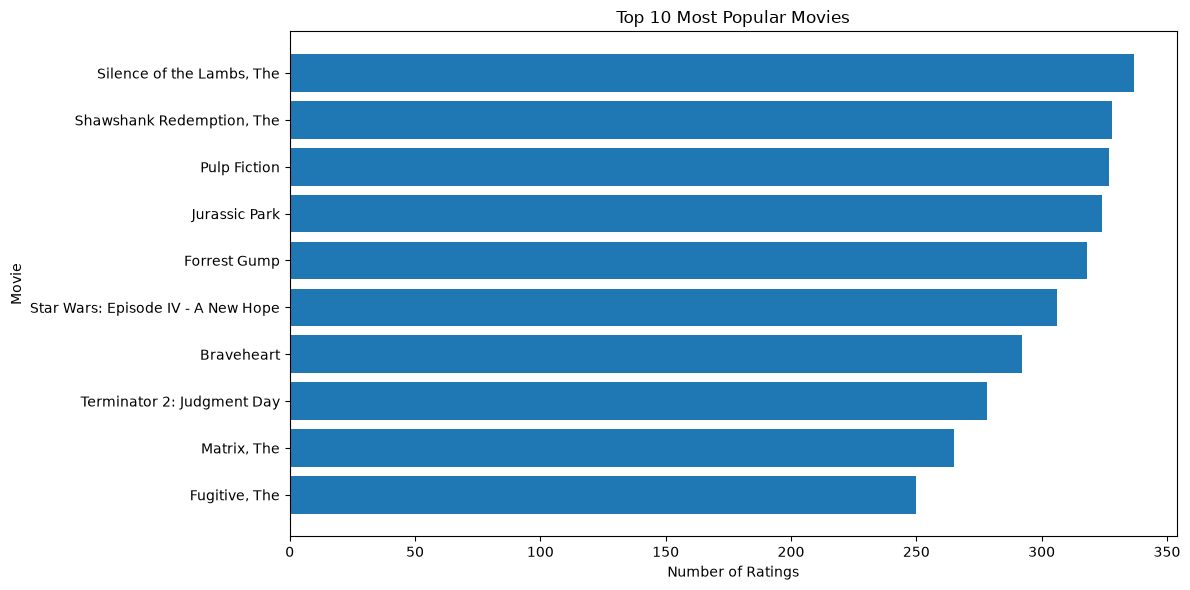

In [32]:
popularity_pd = movie_popularity.limit(10).toPandas()

plt.figure(figsize=(12, 6))

plt.barh(
    popularity_pd["title"][::-1],
    popularity_pd["rating_count"][::-1]
)

plt.xlabel("Number of Ratings")
plt.ylabel("Movie")
plt.title("Top 10 Most Popular Movies")
plt.tight_layout()
plt.show()

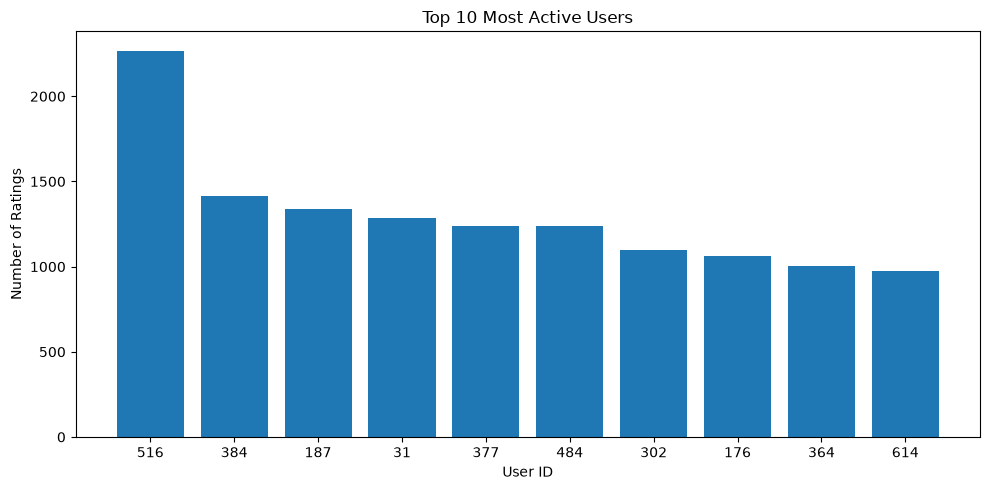

In [33]:
active_users_pd = active_users.limit(10).toPandas()

plt.figure(figsize=(10, 5))

plt.bar(
    active_users_pd["userId"].astype(str),
    active_users_pd["total_ratings"]
)

plt.xlabel("User ID")
plt.ylabel("Number of Ratings")
plt.title("Top 10 Most Active Users")
plt.tight_layout()
plt.show()

In [34]:
rating_distribution.show()

+------+-----+
|rating|count|
+------+-----+
|   0.5| 1284|
|   1.0| 3857|
|   1.5| 1389|
|   2.0| 7255|
|   2.5| 4354|
|   3.0|22803|
|   3.5|11184|
|   4.0|26430|
|   4.5| 6738|
|   5.0|14729|
+------+-----+



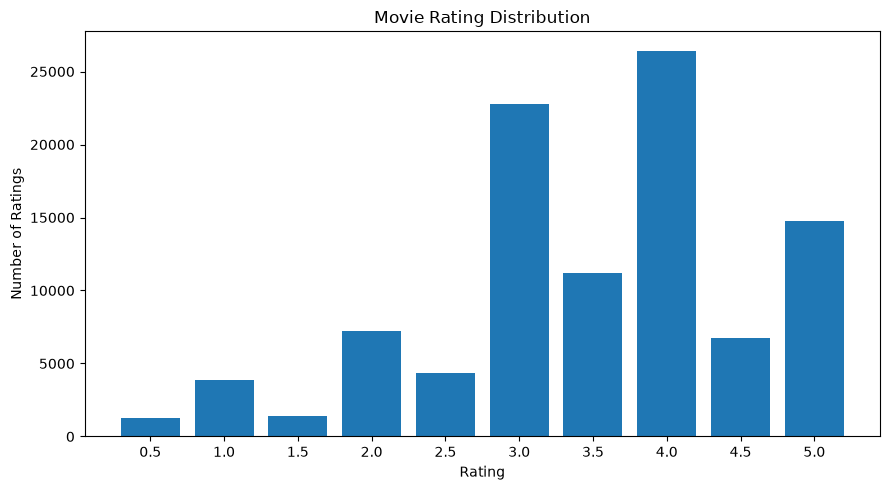

In [35]:
rating_distribution_pd = rating_distribution.toPandas()

plt.figure(figsize=(9, 5))

plt.bar(
    rating_distribution_pd["rating"].astype(str),
    rating_distribution_pd["count"]
)

plt.xlabel("Rating")
plt.ylabel("Number of Ratings")
plt.title("Movie Rating Distribution")
plt.tight_layout()
plt.show()

In [36]:
# Select required columns for ALS
als_data = ratings_spark.select(
    "userId",
    "movieId",
    "rating"
)

# Check the data
als_data.show(10)

print("Total ratings:", als_data.count())

+------+-------+------+
|userId|movieId|rating|
+------+-------+------+
|     1|      6|   2.0|
|     1|     22|   3.0|
|     1|     32|   2.0|
|     1|     50|   5.0|
|     1|    110|   4.0|
|     1|    164|   3.0|
|     1|    198|   3.0|
|     1|    260|   5.0|
|     1|    296|   4.0|
|     1|    303|   3.0|
+------+-------+------+
only showing top 10 rows

Total ratings: 100023


In [37]:
train_data, test_data = als_data.randomSplit(
    [0.8, 0.2],
    seed=42
)

print("Training records:", train_data.count())
print("Testing records:", test_data.count())

Training records: 80084
Testing records: 19939


In [38]:
from pyspark.ml.recommendation import ALS

als = ALS(
    userCol="userId",
    itemCol="movieId",
    ratingCol="rating",
    rank=10,
    maxIter=10,
    regParam=0.1,
    coldStartStrategy="drop",
    seed=42
)

# Train the model
als_model = als.fit(train_data)

print("ALS Model trained successfully!")

ALS Model trained successfully!


In [39]:
from pyspark.ml.evaluation import RegressionEvaluator

predictions = als_model.transform(test_data)

evaluator = RegressionEvaluator(
    metricName="rmse",
    labelCol="rating",
    predictionCol="prediction"
)

rmse = evaluator.evaluate(predictions)

print("Root Mean Squared Error (RMSE):", rmse)

Root Mean Squared Error (RMSE): 0.9511424280257927


<a href="https://colab.research.google.com/github/aysekonus/movie_recommendation_system/blob/main/Huawei_Internship_Task.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [40]:

# Convert Pandas DataFrames into Spark DataFrames

movies_spark = spark.createDataFrame(movies_pd)
ratings_spark = spark.createDataFrame(ratings_pd)
links_spark = spark.createDataFrame(links_pd)
tags_spark = spark.createDataFrame(tags_pd)

print("All datasets converted into Spark DataFrames!")


All datasets converted into Spark DataFrames!


In [41]:

print("Movies:", movies_spark.count())
print("Ratings:", ratings_spark.count())
print("Links:", links_spark.count())
print("Tags:", tags_spark.count())


Movies: 8570
Ratings: 100023
Links: 8570
Tags: 2488


In [47]:
import sqlite3
import os

DB_PATH = r"D:\movie_recommendation_system-main\movielens-small.db"

con = sqlite3.connect(DB_PATH)
cursor = con.cursor()

print("Database connected successfully!")
print("Database path:", DB_PATH)

Database connected successfully!
Database path: D:\movie_recommendation_system-main\movielens-small.db


## DATASET INFORMATION:
---
- **ratings.csv**
```
userId, movieId, rating, timestamp
```
- **tags.csv**
```
userId, movieId, tag, timestamp
```
- **movies.csv**
```
movieId, title, year, genres
```
- **links.csv**
```
movieId, imdbId, tmdbId
```

# **TASK - 1: Exploratory Data Analysis**
---
- **Write a SQL query to create a dataframe with including userid, movieid, genre and rating** : `read_dataframe()`
- **Count ratings for each movie, and list top 5 movies with the highest value** : `list_top5count_movies()`
- **Find and list top 5 most rated genres** : `list_top5rated_genres()`

In [48]:
# function to create dataframe with including userid, movieid, genre and rating
def read_dataframe():
  cursor.execute("SELECT ratings.userId, ratings.movieid, movies.genres, ratings.rating FROM ratings JOIN movies ON ratings.movieId = movies.movieId")
  data = cursor.fetchall()

  print("USER_ID, MOVIE_ID, GENRE, RATING\n--------------------------------------------")
  for i in data:
    print(i)

# function to create dataframe that has count ratings for each movie and list top 5 movies with the highest value of count ratings
def list_top5count_movies():
  cursor.execute("SELECT title, COUNT(rating) as count_rating FROM movies m JOIN ratings r ON m.movieId = r.movieId GROUP BY title ORDER BY count_rating DESC LIMIT 5")
  data = cursor.fetchall()

  print("(MOVIE TITLE, COUNT OF RATING)\n-------------------------------")
  for i in data:
    print(i)

# function to find and list top 5 most rated genres
def list_top5rated_genres():
  cursor.execute("SELECT genres, SUM(rating) as Sum_Rating FROM movies m JOIN ratings r ON m.movieId = r.movieId GROUP BY genres ORDER BY Sum_Rating DESC LIMIT 5")
  data = cursor.fetchall()

  print("(MOVIE GENRE, SUM OF RATINGS)\n-------------------------------")
  for i in data:
    print(i)

In [49]:
# read_dataframe()
# list_top5count_movies()
list_top5rated_genres()

(MOVIE GENRE, SUM OF RATINGS)
-------------------------------
('Drama', 25650.0)
('Comedy', 20529.5)
('Comedy|Romance', 12930.5)
('Drama|Romance', 11295.5)
('Comedy|Drama', 10709.5)


# **TASK - 2: Recommender Design**
---

- **Train a recommender model, one by using user ratings (please prefer a model under PySpark MLlib)**
- **Present your model outputs by using essential metrics**

> ## Requirements
```
!pip install pyspark
```





In [44]:
!pip install pyspark


[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: C:\Users\Lenovo\AppData\Local\Programs\Python\Python312\python.exe -m pip install --upgrade pip


In [50]:
# for machine learning processes
from pyspark.ml.evaluation import RegressionEvaluator
from pyspark.ml.recommendation import ALS
from pyspark.ml.tuning import TrainValidationSplit, ParamGridBuilder

# for dataframe and spark session processes
from pyspark.sql import SparkSession
from pyspark.sql.functions import * 
from pyspark.sql.types import *
from pyspark.context import SparkContext
from datetime import date, timedelta, datetime
import time

> **Functions required to create the dataset file containing the rating data (User_Id, Movie_Id, Rating) required for the recommendation system model:**

- **`create_table()`** : to create the dataset file
- **`insert_data()`** : to transfer data from the database to the data set created
- **`ratings_show()`** : displays data to verify that the dataset has been created




In [52]:
def create_table():
    cursor.execute("""
        CREATE TABLE IF NOT EXISTS movie_ratings (
            User_Id INT,
            Movie_Id INT,
            Rating FLOAT
        )
    """)
    con.commit()


def insert_data():
    cursor.execute("SELECT COUNT(*) FROM movie_ratings")
    count = cursor.fetchone()[0]

    if count == 0:
        cursor.execute("""
            INSERT INTO movie_ratings (User_Id, Movie_Id, Rating)
            SELECT r.userId, r.movieId, r.rating
            FROM ratings r
        """)
        con.commit()


def ratings_show():
    cursor.execute("SELECT * FROM movie_ratings LIMIT 5")
    for row in cursor.fetchall():
        print(row)


create_table()
insert_data()
ratings_show()

(7, 1, 5.0)
(10, 1, 4.0)
(13, 1, 4.5)
(16, 1, 5.0)
(21, 1, 5.0)


> **Functions required to create the dataset file containing the movie informations (Movie Id, Movie Genre and Movie Title) required for the recommendation system model:**

- **`create_table()`** : to create the dataset file
- **`insert_data()`** : to transfer data from the database to the data set created
- **`movies_show()`** : displays data to verify that the dataset has been created


In [53]:
def create_table():
    cursor.execute("""
        CREATE TABLE IF NOT EXISTS movies_2 (
            Movie_Id INT,
            Genres VARCHAR(255),
            Title VARCHAR(255)
        )
    """)
    con.commit()


def insert_data():
    cursor.execute("SELECT COUNT(*) FROM movies_2")
    count = cursor.fetchone()[0]

    if count == 0:
        cursor.execute("""
            INSERT INTO movies_2 (Movie_Id, Genres, Title)
            SELECT movieId, genres, title FROM movies
        """)
        con.commit()


def movies_show():
    cursor.execute("SELECT * FROM movies_2 LIMIT 5")
    data = cursor.fetchall()

    for row in data:
        print(row)


# Execute functions in the correct order
create_table()
insert_data()
movies_show()

(1, 'Adventure|Animation|Children|Comedy|Fantasy', 'Toy Story')
(2, 'Adventure|Children|Fantasy', 'Jumanji')
(3, 'Comedy|Romance', 'Grumpier Old Men')
(4, 'Comedy|Drama|Romance', 'Waiting to Exhale')
(5, 'Comedy', 'Father of the Bride Part II')


In [54]:
# to start spark session
spark = SparkSession.builder.appName('Recommendations').getOrCreate()

## **1.** Load The Datasets

> **The file - folder relationship is as shown in the figure:**

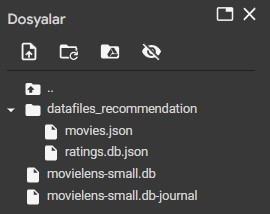

In [55]:
from pyspark.sql.functions import col

# Create DataFrames using the existing SQLite-loaded Spark DataFrames
ratings = ratings_spark.select(
    col("userId").alias("User_Id"),
    col("movieId").alias("Movie_Id"),
    col("rating").alias("Rating")
)

movies = movies_spark.select(
    col("movieId").alias("Movie_Id"),
    col("genres").alias("Genres"),
    col("title").alias("Title")
)

print("Datasets loaded successfully!")

Datasets loaded successfully!


In [56]:
print("Ratings:")
ratings.show(5)

print("Movies:")
movies.show(5, truncate=False)

print("Total ratings:", ratings.count())
print("Total movies:", movies.count())

Ratings:
+-------+--------+------+
|User_Id|Movie_Id|Rating|
+-------+--------+------+
|      1|       6|   2.0|
|      1|      22|   3.0|
|      1|      32|   2.0|
|      1|      50|   5.0|
|      1|     110|   4.0|
+-------+--------+------+
only showing top 5 rows

Movies:
+--------+-------------------------------------------+---------------------------+
|Movie_Id|Genres                                     |Title                      |
+--------+-------------------------------------------+---------------------------+
|1       |Adventure|Animation|Children|Comedy|Fantasy|Toy Story                  |
|2       |Adventure|Children|Fantasy                 |Jumanji                    |
|3       |Comedy|Romance                             |Grumpier Old Men           |
|4       |Comedy|Drama|Romance                       |Waiting to Exhale          |
|5       |Comedy                                     |Father of the Bride Part II|
+--------+-------------------------------------------+------

In [57]:
# to verify that it was created correctly by viewing part of the dataset

ratings.show(3)
# ratings.printSchema()
# ratings.describe().show()

+-------+--------+------+
|User_Id|Movie_Id|Rating|
+-------+--------+------+
|      1|       6|   2.0|
|      1|      22|   3.0|
|      1|      32|   2.0|
+-------+--------+------+
only showing top 3 rows



In [58]:
# to verify that it was created correctly by viewing part of the dataset

movies.show(3)
# movies.printSchema()
# movies.describe().show()

+--------+--------------------+----------------+
|Movie_Id|              Genres|           Title|
+--------+--------------------+----------------+
|       1|Adventure|Animati...|       Toy Story|
|       2|Adventure|Childre...|         Jumanji|
|       3|      Comedy|Romance|Grumpier Old Men|
+--------+--------------------+----------------+
only showing top 3 rows



### **To examine the density status of the dataset (sparsity)**

In [59]:
# Count the total number of ratings in the dataset
numerator = ratings.select("Rating").count() 

# Count the number of distinct User_Ids and distinct Movie_Ids
num_users = ratings.select("User_Id").distinct().count()
num_movies = ratings.select("Movie_Id").distinct().count()

# Set the denominator equal to the number of users multiplied by the number of movies
denominator = num_users * num_movies

# Divide the numerator by the denominator
sparsity = (1.0 - (numerator *1.0)/denominator)*100
print("The ratings dataframe is", "%.2f" % sparsity + "% empty.")

The ratings dataframe is 98.34% empty.


### **To interpret ratings**

> **To find out how many ratings users generally have for movies and to see how many ratings each movie has**

In [60]:
userId_ratings = ratings.groupBy("User_Id").count().orderBy('count', ascending=False)
userId_ratings.show(5)

+-------+-----+
|User_Id|count|
+-------+-----+
|    516| 2268|
|    384| 1412|
|    187| 1338|
|     31| 1283|
|    377| 1241|
+-------+-----+
only showing top 5 rows



In [61]:
# Group data by userId, count ratings
movieId_ratings = ratings.groupBy("Movie_Id").count().orderBy('count', ascending=False)
movieId_ratings.show(5)

+--------+-----+
|Movie_Id|count|
+--------+-----+
|     593|  337|
|     318|  328|
|     296|  327|
|     480|  324|
|     356|  318|
+--------+-----+
only showing top 5 rows



## 2- **Let's Build Out An Alternating Least Square Model for Recommendation System**



In [62]:
# Create test and train set
(train, test) = ratings.randomSplit([0.7, 0.3], seed=42)

# Create Alternating Least Square Model
als = ALS(userCol="User_Id", itemCol="Movie_Id", ratingCol="Rating", coldStartStrategy="drop", nonnegative=True)

### Configure Spark to tune ALS model


In [63]:
# hyperparameters and their respective values to param_grid
param_grid = ParamGridBuilder()\
            .addGrid(als.rank, [12,13,14])\
            .addGrid(als.maxIter, [18,19,20])\
            .addGrid(als.regParam, [.17, .18, .19])\
            .build()

# Defining evaluator as RMSE and print length of evaluator
evaluator = RegressionEvaluator(metricName="rmse", labelCol="Rating", predictionCol="prediction")

In [64]:
# to build validation pipeline
tvs = TrainValidationSplit(estimator=als,
                           estimatorParamMaps=param_grid,
                           evaluator=evaluator)

### **To set best model and best model parameters for recommendation system**

In [ ]:
# model = tvs.fit(train)


from pyspark.ml.tuning import ParamGridBuilder, TrainValidationSplit
from pyspark.ml.evaluation import RegressionEvaluator

paramGrid = (
    ParamGridBuilder()
    .addGrid(als.rank, [10, 12])
    .addGrid(als.maxIter, [10, 15])
    .addGrid(als.regParam, [0.1, 0.2])
    .build()
)

evaluator = RegressionEvaluator(
    metricName="rmse",
    labelCol="Rating",
    predictionCol="prediction"
)

tvs = TrainValidationSplit(
    estimator=als,
    estimatorParamMaps=paramGrid,
    evaluator=evaluator,
    trainRatio=0.8,
    parallelism=1
)

print("Hyperparameter tuning configured successfully!")
print("Number of combinations:", len(paramGrid))

Hyperparameter tuning configured successfully!
Number of combinations: 8


In [66]:
print("Training data schema:")
train.printSchema()

print("Training records:", train.count())

train.show(5)

Training data schema:
root
 |-- User_Id: long (nullable = true)
 |-- Movie_Id: long (nullable = true)
 |-- Rating: double (nullable = true)

Training records: 70189
+-------+--------+------+
|User_Id|Movie_Id|Rating|
+-------+--------+------+
|      1|       6|   2.0|
|      1|      22|   3.0|
|      1|      50|   5.0|
|      1|     110|   4.0|
|      1|     164|   3.0|
+-------+--------+------+
only showing top 5 rows



In [68]:
model = tvs.fit(train)

In [69]:
best_model = model.bestModel

In [70]:
test_predictions = best_model.transform(test)
test_predictions.show()

+-------+--------+------+----------+
|User_Id|Movie_Id|Rating|prediction|
+-------+--------+------+----------+
|     31|    1580|   3.0|  2.481749|
|     31|    3175|   3.0|  2.559738|
|    193|     471|   3.5| 3.9267337|
|    332|    1645|   3.0| 3.1822193|
|    159|     471|   4.0|  3.657239|
|    103|    1959|   5.0|  3.787472|
|    236|    1580|   3.5| 3.5859172|
|    285|     471|   4.5|  3.363501|
|    330|    1591|   4.0| 2.5413783|
|    330|    1645|   4.5| 3.2942207|
|    330|    2122|   4.5| 2.9866743|
|    230|     471|   4.5| 2.7208111|
|    177|     471|   2.0| 2.7249033|
|    177|    1645|   4.0| 2.5567727|
|    177|    1829|   2.0| 1.5768689|
|    152|    1580|   3.0| 3.8531868|
|    325|    3997|   2.0| 1.2535801|
|    259|    1088|   4.0| 3.2444959|
|      1|    1580|   5.0| 3.1937008|
|     52|    1342|   4.0| 2.4521933|
+-------+--------+------+----------+
only showing top 20 rows



In [71]:
# View the predictions
RMSE = evaluator.evaluate(test_predictions)
print(RMSE)

0.9443401262183286


In [72]:
print("Best Model")
print("-------------")

print("  Rank:", best_model._java_obj.parent().getRank())
print("  MaxIter:", best_model._java_obj.parent().getMaxIter())
print("  RegParam:", best_model._java_obj.parent().getRegParam())

Best Model
-------------
  Rank: 12
  MaxIter: 15
  RegParam: 0.2


## **3- Create The Recommendation System**

In [73]:
# Generate n (ex: 10) Recommendations for all users

nrecommendations = best_model.recommendForAllUsers(10)
nrecommendations.limit(10).show()

+-------+--------------------+
|User_Id|     recommendations|
+-------+--------------------+
|      1|[{57910, 4.523838...|
|      2|[{7341, 5.4031916...|
|      3|[{7341, 5.8375773...|
|      4|[{7341, 4.9543567...|
|      5|[{70992, 5.030748...|
|      6|[{115170, 4.72366...|
|      7|[{7341, 5.626438}...|
|      8|[{7341, 5.23416},...|
|      9|[{7341, 5.2843914...|
|     10|[{824, 4.921349},...|
+-------+--------------------+



In [74]:
# to split the recommendation column into 2 separate columns to bring the table to the format we want

nrecommendations = nrecommendations\
    .withColumn("rec_exp", explode("recommendations"))\
    .select('User_Id', col("rec_exp.Movie_Id"), col("rec_exp.Rating"))

nrecommendations.limit(10).show()

+-------+--------+---------+
|User_Id|Movie_Id|   Rating|
+-------+--------+---------+
|      1|   57910|4.5238385|
|      1|   33451|4.5238385|
|      1|    7070|4.4492035|
|      1|    7341|4.4490457|
|      1|   31785|4.4286637|
|      1|    6140| 4.339656|
|      1|    4710|4.2784343|
|      1|     824|4.2759633|
|      1|    8491|4.2582483|
|      1|   70992|4.2071986|
+-------+--------+---------+



## 4- RECOMMENDATION SYSTEM

> **Movie recommendation system that filters the User_Id information according to the user we want and lists the most compatible movies for that user.**

Please edit the filter `.filter("User_Id = N")` with the **user's ID** (N) according to the user you want.

In [75]:
nrecommendations.join(movies, on='Movie_Id').filter('User_Id = 100').sort('rating', ascending=False).limit(10).show()

+--------+-------+---------+--------------------+--------------------+
|Movie_Id|User_Id|   Rating|              Genres|               Title|
+--------+-------+---------+--------------------+--------------------+
|    7341|    100|5.2458653|Crime|Drama|Thriller|           The Chase|
|   31785|    100|5.1497746|               Drama|Frozen Land (Paha...|
|    1858|    100|5.1453004|       Action|Comedy|Mr. Nice Guy (Yat...|
|    7070|    100|5.1451106|Action|Adventure|...|           Red River|
|     824|    100|5.0954084|       Drama|Mystery|       Kaspar Hauser|
|   57910|    100|4.9175434|       Comedy|Horror|               Teeth|
|   33451|    100|4.9175434|        Comedy|Drama|Ugly, Dirty and B...|
|    4710|    100|  4.91392|       Drama|Western|       Shootist, The|
|    5792|    100|4.9038086|        Comedy|Drama|        Roger Dodger|
|   31435|    100|4.8362956|               Drama|Rory O'Shea Was H...|
+--------+-------+---------+--------------------+--------------------+

